## Задание 1

In [52]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)


In [53]:
class Identity(nn.Module):
    def forward(self, x):
        return x

class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=[512, 256, 256, 128]):
        """
        Inputs:
            act_fn - Объект функции активации
            input_size - Размер входного вектора (28*28 = 784)
            num_classes - Количество классов (10)
            hidden_sizes - Список размеров скрытых слоев
        """
        super().__init__()
        layers = []
        layer_sizes = [input_size] + hidden_sizes
        
        for layer_index in range(1, len(layer_sizes)):
            layers += [
                nn.Linear(layer_sizes[layer_index-1], layer_sizes[layer_index]),
                act_fn
            ]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)

        self.config = {
            "act_fn": act_fn.__class__.__name__,
            "input_size": input_size,
            "num_classes": num_classes,
            "hidden_sizes": hidden_sizes
        }

    def forward(self, x):
        x = x.view(x.size(0), -1)
        activations = []
        
        for layer in self.layers:
            x = layer(x)
            if not isinstance(layer, nn.Linear):
                activations.append(x)
                
        return x, activations

In [54]:
def apply_initialization(model, init_type):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            if init_type == 'constant':
                nn.init.constant_(m.weight, 0.2)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)
            elif init_type == 'random':
                nn.init.normal_(m.weight, mean=0.0, std=0.05)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)
            elif init_type == 'xavier':
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)
            elif init_type == 'kaiming':
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)
            else:
                raise ValueError(f"Неизвестный тип инициализации: {init_type}")

In [55]:
def safe_hist(ax, data, bins=40, color='#2b5c8f', alpha=0.7):
    data = np.asarray(data)
    if len(data) == 0:
        return
    
    min_val, max_val = np.min(data), np.max(data)
    
    if np.isclose(min_val, max_val):
        ax.hist(data, bins=bins, range=(min_val - 1.0, max_val + 1.0), color=color, alpha=alpha)
    else:
        ax.hist(data, bins=bins, color=color, alpha=alpha)


def plot_layer_stats(act_fn, init_type):
    model = BaseNetwork(act_fn).to(device)
    apply_initialization(model, init_type)
    
    inputs, targets = next(iter(train_loader))
    inputs, targets = inputs.to(device), targets.to(device)
    
    outputs, activations = model(inputs)
    loss = nn.CrossEntropyLoss()(outputs, targets)

    model.zero_grad()
    loss.backward()

    gradients = [layer.weight.grad.detach().cpu().numpy().flatten() 
                 for layer in model.layers if isinstance(layer, nn.Linear)]
    act_values = [act.detach().cpu().numpy().flatten() for act in activations]
    
    num_layers = len(act_values)
    
    fig, axes = plt.subplots(2, num_layers, figsize=(4 * num_layers, 6))
    act_name = act_fn.__class__.__name__
    fig.suptitle(f"Активация: {act_name} | Инициализация: {init_type}", fontsize=14, fontweight='bold')
    
    for i in range(num_layers):
        safe_hist(axes[0, i], act_values[i], bins=40, color='#2b5c8f', alpha=0.7)
        axes[0, i].set_title(f"Активация (Слой {i+1})")
        axes[0, i].grid(True, linestyle='--', alpha=0.5)
        
        safe_hist(axes[1, i], gradients[i], bins=40, color='#d95f02', alpha=0.7)
        axes[1, i].set_title(f"Градиент (Слой {i+1})")
        axes[1, i].grid(True, linestyle='--', alpha=0.5)
        
    plt.tight_layout()
    plt.show()

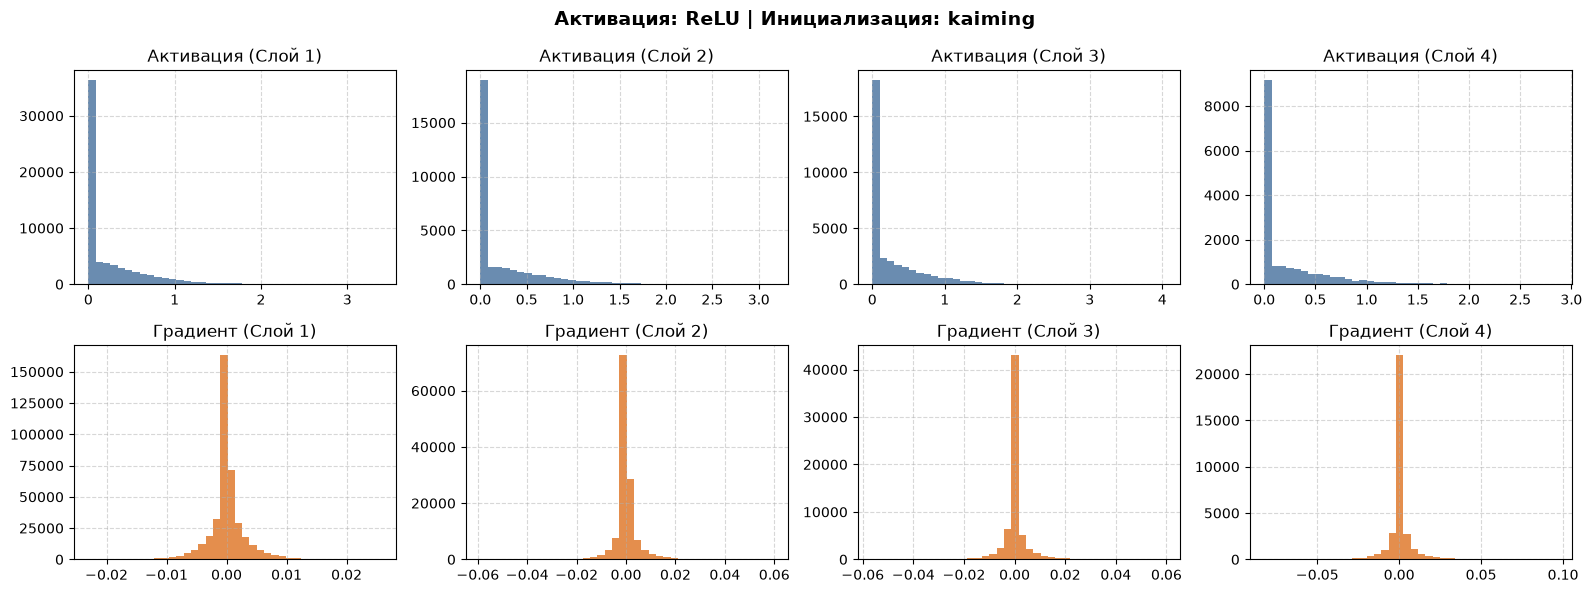

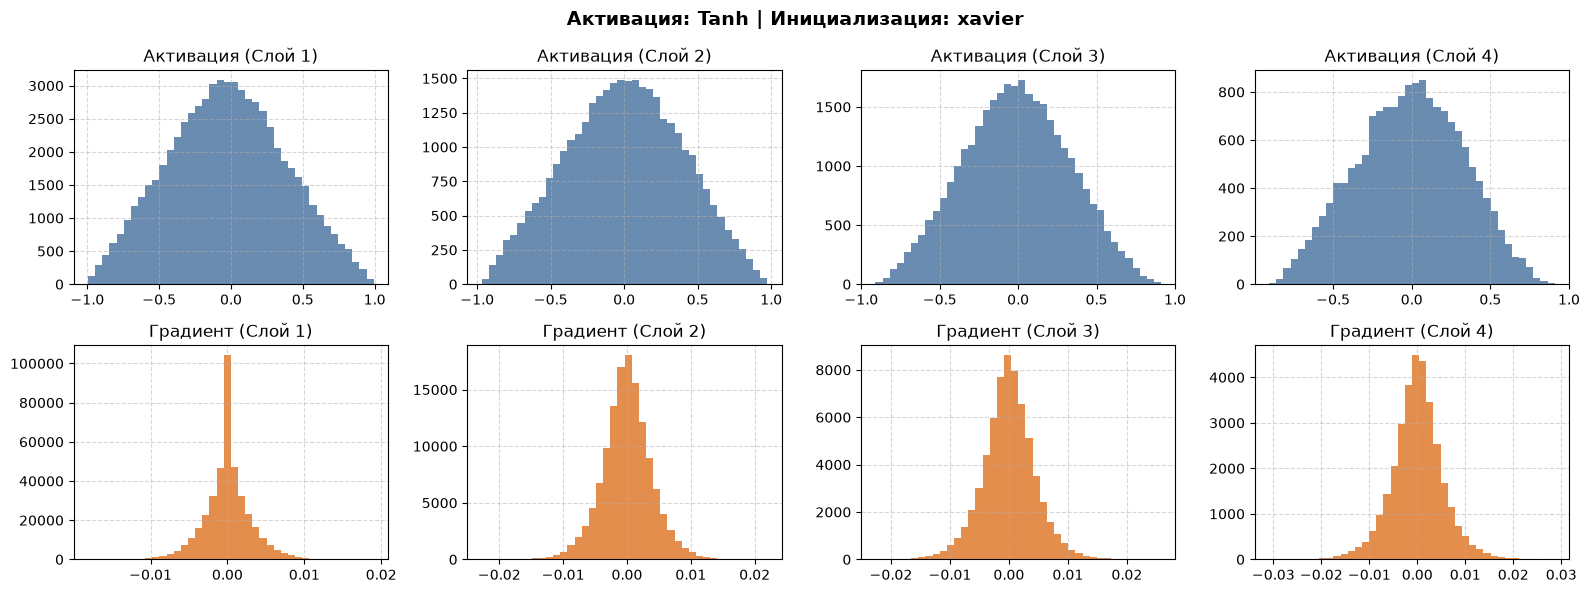

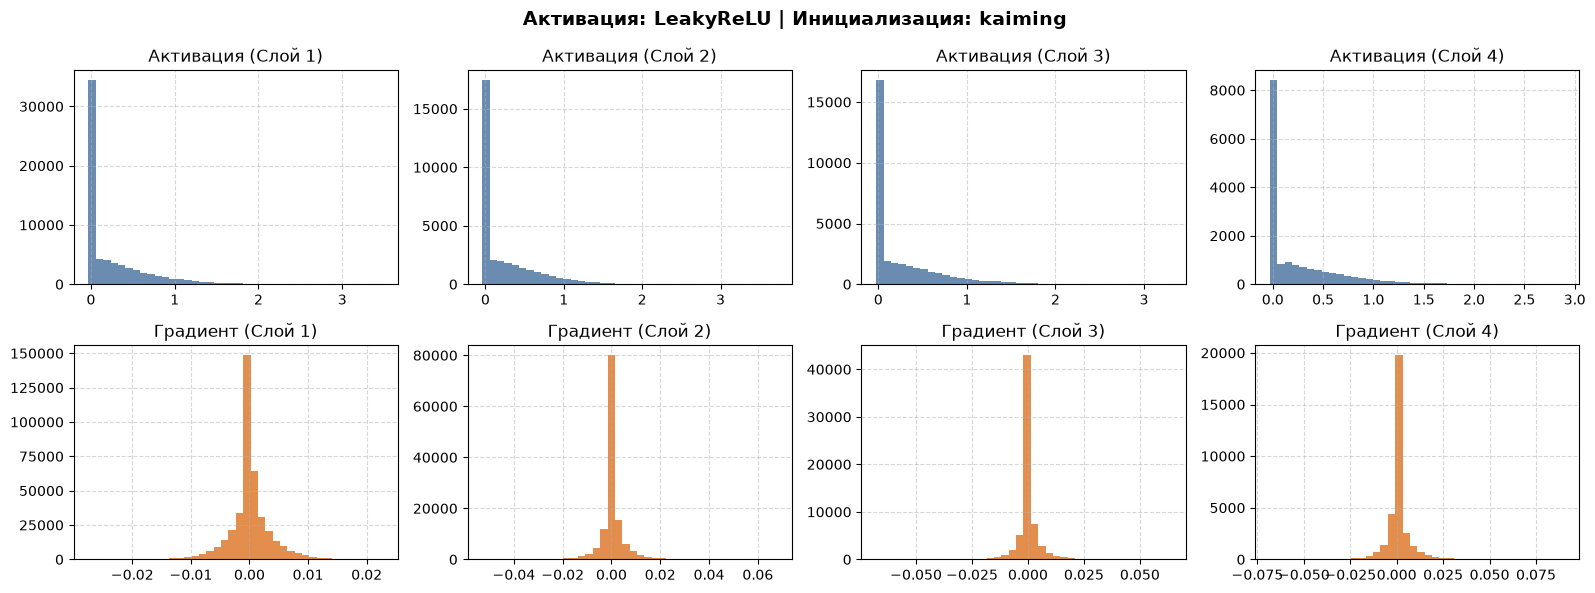

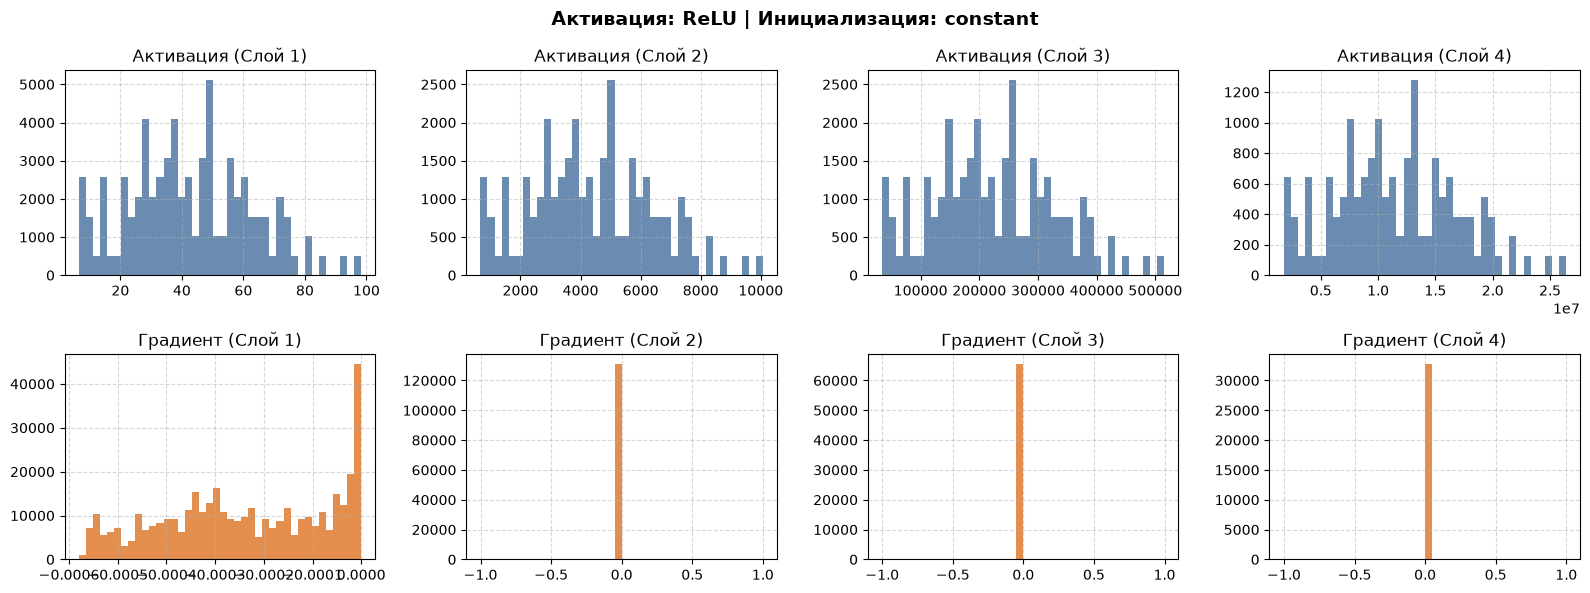

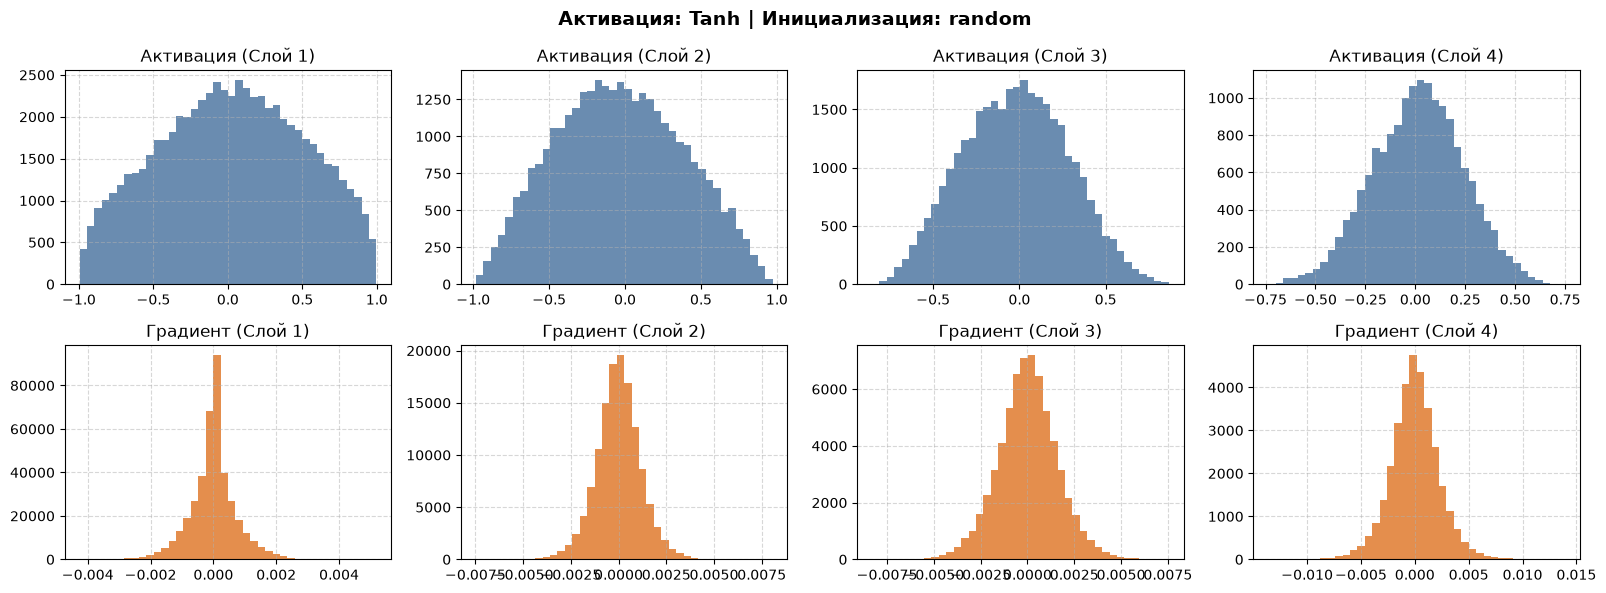

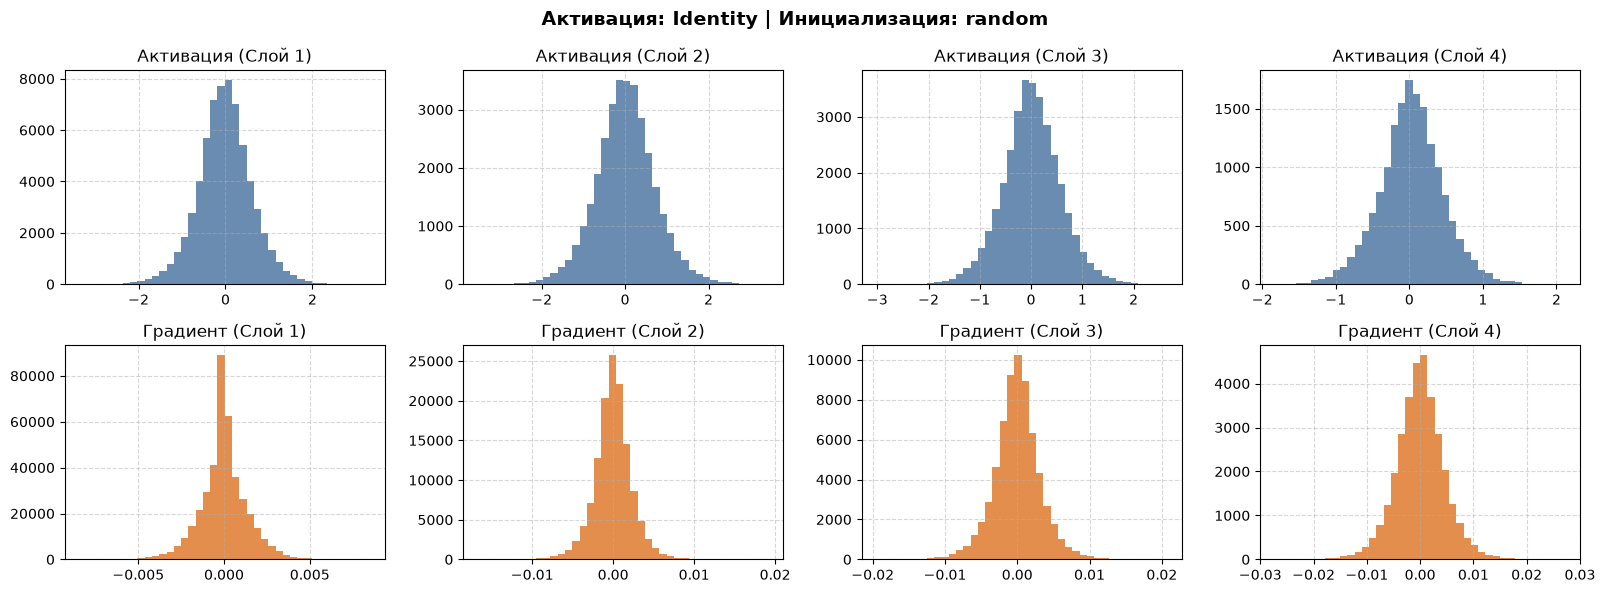

In [56]:
plot_layer_stats(nn.ReLU(), 'kaiming')       
plot_layer_stats(nn.Tanh(), 'xavier')         
plot_layer_stats(nn.LeakyReLU(), 'kaiming') #дополнительный   

plot_layer_stats(nn.ReLU(), 'constant')       
plot_layer_stats(nn.Tanh(), 'random')      
plot_layer_stats(Identity(), 'random') 



Обучение конфигурации: ReLU + Kaiming...
Обучение конфигурации: Tanh + Xavier...
Обучение конфигурации: LeakyReLU + Kaiming...
Обучение конфигурации: Identity + Xavier...
Обучение конфигурации: ReLU + Constant...
Обучение конфигурации: Tanh + Random...


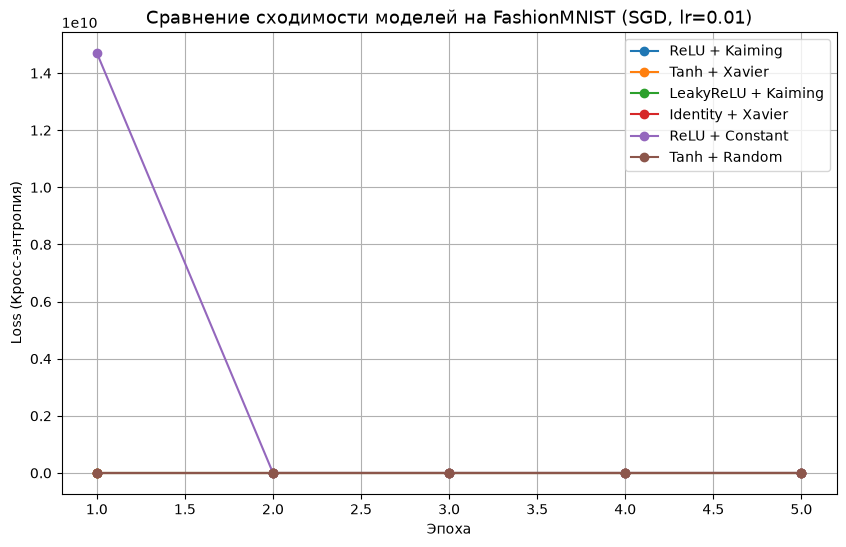

In [57]:
def train_model(act_fn, init_type, epochs=5, lr=0.01):
    model = BaseNetwork(act_fn).to(device)
    apply_initialization(model, init_type)
    
    optimizer = optim.SGD(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    history_loss = []
    
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs, _ = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            
        epoch_loss = running_loss / len(train_loader)
        history_loss.append(epoch_loss)
        
    return history_loss

experiments = [
    (nn.ReLU(), 'kaiming', 'ReLU + Kaiming'),
    (nn.Tanh(), 'xavier', 'Tanh + Xavier'),
    (nn.LeakyReLU(), 'kaiming', 'LeakyReLU + Kaiming'),
    (Identity(), 'xavier', 'Identity + Xavier'),
    (nn.ReLU(), 'constant', 'ReLU + Constant'),
    (nn.Tanh(), 'random', 'Tanh + Random')
]

plt.figure(figsize=(10, 6))

for act_fn, init_type, label in experiments:
    print(f"Обучение конфигурации: {label}...")
    losses = train_model(act_fn, init_type, epochs=5, lr=0.01)
    plt.plot(range(1, 6), losses, marker='o', label=label)

plt.title('Сравнение сходимости моделей на FashionMNIST (SGD, lr=0.01)', fontsize=13)
plt.xlabel('Эпоха')
plt.ylabel('Loss (Кросс-энтропия)')
plt.legend()
plt.grid(True)
plt.show()

## Задание 2

In [ ]:
import torch

class Node:
    def __init__(self, data, _children=(), _op=''):
        if isinstance(data, torch.Tensor):
            self.data = float(data.item())
        else:
            self.data = float(data)
            
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op

    def __repr__(self):
        return f"Node(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)

    def relu(self):
        out = Node(max(0.0, self.data), (self,), 'ReLU')

        def _backward():
            self.grad += (self.data > 0) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [59]:
a = Node(2)
b = Node(-3)
c = Node(10)

d = a + b * c
e = d.relu()
e.backward()

print("Результаты вычислений:")
print(f"a = {a}")
print(f"b = {b}")
print(f"c = {c}")
print(f"d = {d}")
print(f"e = {e}")

Результаты вычислений:
a = Node(data=2.0, grad=0.0)
b = Node(data=-3.0, grad=0.0)
c = Node(data=10.0, grad=0.0)
d = Node(data=-28.0, grad=0.0)
e = Node(data=0.0, grad=1.0)


In [60]:
import unittest

class TestAutogradNode(unittest.TestCase):
    
    def test_addition(self):
        a = Node(3.0)
        b = Node(4.0)
        c = a + b
        c.backward()
        
        self.assertEqual(c.data, 7.0)
        self.assertEqual(a.grad, 1.0)
        self.assertEqual(b.grad, 1.0)

    def test_multiplication(self):
        a = Node(3.0)
        b = Node(4.0)
        c = a * b
        c.backward()
        
        self.assertEqual(c.data, 12.0)
        self.assertEqual(a.grad, 4.0)
        self.assertEqual(b.grad, 3.0)

    def test_relu_positive(self):
        a = Node(3.0)
        b = a.relu()
        b.backward()
        
        self.assertEqual(b.data, 3.0)
        self.assertEqual(a.grad, 1.0)

    def test_relu_negative(self):
        a = Node(-3.0)
        b = a.relu()
        b.backward()
        
        self.assertEqual(b.data, 0.0)
        self.assertEqual(a.grad, 0.0)

    def test_complex_expression_compared_with_pytorch(self):
        x1 = Node(2.0)
        x2 = Node(-3.0)
        w1 = Node(-1.0)
        w2 = Node(4.0)
        b = Node(6.0)
        
        out_node = (x1 * w1 + x2 * w2 + b).relu()
        out_node.backward()

        pt_x1 = torch.tensor([2.0], requires_grad=True)
        pt_x2 = torch.tensor([-3.0], requires_grad=True)
        pt_w1 = torch.tensor([-1.0], requires_grad=True)
        pt_w2 = torch.tensor([4.0], requires_grad=True)
        pt_b  = torch.tensor([6.0], requires_grad=True)

        pt_out = torch.relu(pt_x1 * pt_w1 + pt_x2 * pt_w2 + pt_b)
        pt_out.backward()

        self.assertAlmostEqual(out_node.data, pt_out.item())
        self.assertAlmostEqual(x1.grad, pt_x1.grad.item())
        self.assertAlmostEqual(x2.grad, pt_x2.grad.item())
        self.assertAlmostEqual(w1.grad, pt_w1.grad.item())
        self.assertAlmostEqual(w2.grad, pt_w2.grad.item())
        self.assertAlmostEqual(b.grad, pt_b.grad.item())

suite = unittest.TestLoader().loadTestsFromTestCase(TestAutogradNode)
unittest.TextTestRunner(verbosity=2).run(suite)

test_addition (__main__.TestAutogradNode.test_addition) ... ok
test_complex_expression_compared_with_pytorch (__main__.TestAutogradNode.test_complex_expression_compared_with_pytorch) ... ok
test_multiplication (__main__.TestAutogradNode.test_multiplication) ... ok
test_relu_negative (__main__.TestAutogradNode.test_relu_negative) ... ok
test_relu_positive (__main__.TestAutogradNode.test_relu_positive) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.011s

OK


<unittest.runner.TextTestResult run=5 errors=0 failures=0>

## Задание 3

ИДЕИ АЛГОРИТМОВ:

Momentum: Имитирует скатывающийся с горы шар. Он накапливает инерцию прошлых шагов, помогая быстрее преодолевать плоские участки и гасить колебания из стороны в сторону.

RMSProp: Адаптирует скорость обучения индивидуально для каждого параметра. Если параметр обновляется слишком часто и сильно, шаг для него уменьшается, а для редких параметров — увеличивается.

AdamW: Объединяет достоинства инерции (Momentum) и адаптивного шага (RMSProp), а также правильно применяет штраф за слишком большие веса (Weight Decay), улучшая обобщающую способность сети.

Nadam: Улучшенная версия Adam, которая использует эффект заглядывания вперед. Алгоритм сначала делает предварительный шаг по инерции и только потом оценивает градиент.

In [ ]:
import torch

class CustomMomentum:
    def __init__(self, params, lr=0.01, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.velocities = [torch.zeros_like(p.data) for p in self.params]

    def step(self):
        for p, v in zip(self.params, self.velocities):
            if p.grad is None: continue
            g = p.grad.data
            v.data = self.momentum * v.data + g
            p.data -= self.lr * v.data

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.detach_()
                p.grad.zero_()


class CustomRMSProp:
    def __init__(self, params, lr=0.01, alpha=0.99, eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.alpha = alpha
        self.eps = eps
        self.v = [torch.zeros_like(p.data) for p in self.params]

    def step(self):
        for i, p in enumerate(self.params):
            if p.grad is None: continue
            g = p.grad.data
            self.v[i] = self.alpha * self.v[i] + (1 - self.alpha) * (g ** 2)
            p.data -= self.lr * g / (torch.sqrt(self.v[i]) + self.eps)

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.detach_()
                p.grad.zero_()


class CustomAdamW:
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.t = 0
        self.m = [torch.zeros_like(p.data) for p in self.params]
        self.v = [torch.zeros_like(p.data) for p in self.params]

    def step(self):
        self.t += 1
        for i, p in enumerate(self.params):
            if p.grad is None: continue
            g = p.grad.data
            
            p.data -= self.lr * self.weight_decay * p.data
            
            self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
            self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * (g ** 2)
            
            m_hat = self.m[i] / (1 - self.beta1 ** self.t)
            v_hat = self.v[i] / (1 - self.beta2 ** self.t)
            
            p.data -= self.lr * m_hat / (torch.sqrt(v_hat) + self.eps)

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.detach_()
                p.grad.zero_()


class CustomNadam:
    def __init__(self, params, lr=0.002, betas=(0.9, 0.999), eps=1e-8, momentum_decay=0.004):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.momentum_decay = momentum_decay
        self.t = 0
        self.m = [torch.zeros_like(p.data) for p in self.params]
        self.v = [torch.zeros_like(p.data) for p in self.params]
        self.mu_product = 1.0

    def step(self):
        self.t += 1
        
        mu_t = self.beta1 * (1.0 - 0.5 * (0.96 ** (self.t * self.momentum_decay)))
        mu_t1 = self.beta1 * (1.0 - 0.5 * (0.96 ** ((self.t + 1) * self.momentum_decay)))
        self.mu_product *= mu_t
        mu_product_next = self.mu_product * mu_t1

        for i, p in enumerate(self.params):
            if p.grad is None: continue
            g = p.grad.data
            
            self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
            self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * (g ** 2)
            
            g_hat = g / (1.0 - self.mu_product)
            m_hat = self.m[i] / (1.0 - mu_product_next)
            v_hat = self.v[i] / (1.0 - self.beta2 ** self.t)
            
            m_bar = (1.0 - mu_t) * g_hat + mu_t1 * m_hat
            p.data -= self.lr * m_bar / (torch.sqrt(v_hat) + self.eps)

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.detach_()
                p.grad.zero_()

In [62]:
import unittest

class TestAllOptimizers(unittest.TestCase):
    
    def test_momentum(self):
        w_c, w_pt = torch.tensor([2.0], requires_grad=True), torch.tensor([2.0], requires_grad=True)
        opt_c = CustomMomentum([w_c], lr=0.1, momentum=0.9)
        opt_pt = torch.optim.SGD([w_pt], lr=0.1, momentum=0.9)
        for _ in range(3):
            (w_c**2).backward(); (w_pt**2).backward()
            opt_c.step(); opt_pt.step()
            opt_c.zero_grad(); opt_pt.zero_grad()
        self.assertTrue(torch.allclose(w_c, w_pt, atol=1e-4))

    def test_rmsprop(self):
        w_c, w_pt = torch.tensor([2.0], requires_grad=True), torch.tensor([2.0], requires_grad=True)
        opt_c = CustomRMSProp([w_c], lr=0.01)
        opt_pt = torch.optim.RMSprop([w_pt], lr=0.01)
        for _ in range(3):
            (w_c**2).backward(); (w_pt**2).backward()
            opt_c.step(); opt_pt.step()
            opt_c.zero_grad(); opt_pt.zero_grad()
        self.assertTrue(torch.allclose(w_c, w_pt, atol=1e-4))

    def test_adamw(self):
        w_c, w_pt = torch.tensor([2.0], requires_grad=True), torch.tensor([2.0], requires_grad=True)
        opt_c = CustomAdamW([w_c], lr=0.01, weight_decay=0.01)
        opt_pt = torch.optim.AdamW([w_pt], lr=0.01, weight_decay=0.01)
        for _ in range(3):
            (w_c**2).backward(); (w_pt**2).backward()
            opt_c.step(); opt_pt.step()
            opt_c.zero_grad(); opt_pt.zero_grad()
        self.assertTrue(torch.allclose(w_c, w_pt, atol=1e-4))

    def test_nadam(self):
        w_c, w_pt = torch.tensor([2.0], requires_grad=True), torch.tensor([2.0], requires_grad=True)
        opt_c = CustomNadam([w_c], lr=0.002)
        opt_pt = torch.optim.NAdam([w_pt], lr=0.002)
        for _ in range(3):
            (w_c**2).backward(); (w_pt**2).backward()
            opt_c.step(); opt_pt.step()
            opt_c.zero_grad(); opt_pt.zero_grad()
        self.assertTrue(torch.allclose(w_c, w_pt, atol=1e-4))

suite = unittest.TestLoader().loadTestsFromTestCase(TestAllOptimizers)
unittest.TextTestRunner(verbosity=2).run(suite)

test_adamw (__main__.TestAllOptimizers.test_adamw) ... ok
test_momentum (__main__.TestAllOptimizers.test_momentum) ... ok
test_nadam (__main__.TestAllOptimizers.test_nadam) ... ok
test_rmsprop (__main__.TestAllOptimizers.test_rmsprop) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.021s

OK


<unittest.runner.TextTestResult run=4 errors=0 failures=0>

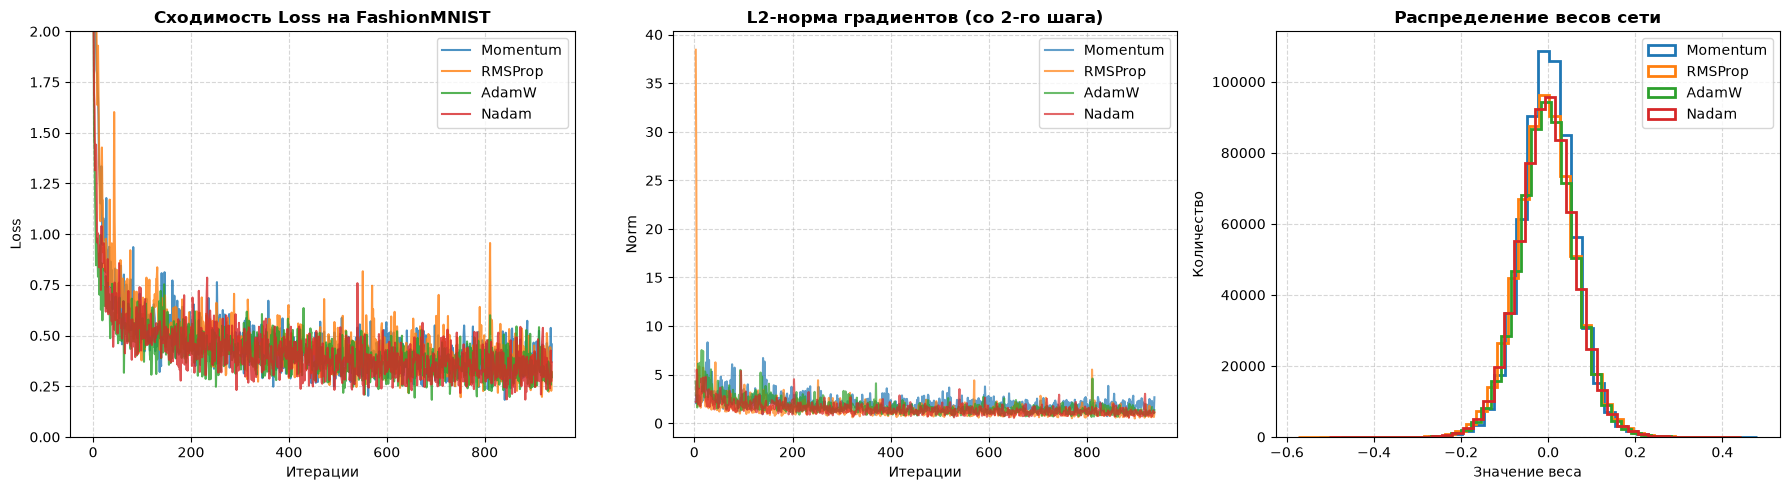

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name in results:
    axes[0].plot(results[name]["losses"], label=name, alpha=0.8)
axes[0].set_title("Сходимость Loss на FashionMNIST", fontweight='bold')
axes[0].set_xlabel("Итерации")
axes[0].set_ylabel("Loss")
axes[0].set_ylim(0, 2.0)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)


for name in results:
    axes[1].plot(range(3, len(results[name]["grad_norms"])), 
                 results[name]["grad_norms"][3:], label=name, alpha=0.7)
axes[1].set_title("L2-норма градиентов (со 2-го шага)", fontweight='bold')
axes[1].set_xlabel("Итерации")
axes[1].set_ylabel("Norm")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

for name in results:
    axes[2].hist(results[name]["weights"], bins=40, histtype='step', linewidth=2, label=name)
axes[2].set_title("Распределение весов сети", fontweight='bold')
axes[2].set_xlabel("Значение веса")
axes[2].set_ylabel("Количество")
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()